# Q2: pairwise tests with Holm's correction for Arena's rank spreads

The [Bonferroni notebook](q2_bonferroni.ipynb) and the [χ² notebook](q2_chi2.ipynb) corrected Arena's rank spreads by widening each model's **score interval** and keeping Arena's rule that two models are ordered only when their intervals do not overlap. This notebook drops the intervals and tests every pair of models directly, as the proposal planned: for each of the $K = 129 \cdot 128/2 = 8{,}256$ pairs, test whether the two scores differ, using the full covariance of the estimates, and control the errors over all pairs with **Holm's step-down procedure**. A model's rank interval then follows from the pairs it is declared above and below.

We run three versions, so that the gain can be traced to its source:

- **Pairwise Bonferroni**: every pair tested at level $0.05/K$. This only replaces the overlap rule with a direct test of each difference.
- **Holm**: the textbook two-sided Holm procedure on the same tests. It starts at the Bonferroni bar and relaxes it as pairs are rejected.
- **Holm (one-sided)**: Holm applied to the $2K$ one-sided statements "A is not above B". Unlike the textbook version, its control of wrong orderings is a theorem under the correlations present here (Section 1).

**Short answer.** In all 1,000 simulated datasets, all three procedures kept every rank interval right. Pairwise Bonferroni and one-sided Holm are valid by theorem, up to the normal approximation. The textbook Holm has no such proof for our correlated tests, so its validity is shown by simulation, and it held in every stress-test world we built. It got all rank intervals right in at least 96.6% of datasets where models are exactly tied (the setting where these guarantees are tight), and in at least 99.4% where they are nearly tied (the setting its proof does not cover). Holm gives the narrowest valid rank intervals of any correction so far: 11.3 ranks on average, against 13.6 for Bonferroni and 33.1 for χ² Scheffé, though still 41% wider than Arena's 8.0. Applied to the 2024 battles, Holm keeps the top three models at single ranks (Bonferroni ties the top two). It does not support 223 of the 7,808 orderings Arena's method declares. It separates no pair that Arena shows as tied.

The numbers come from `q2.py` (`--procedures arena,bonferroni,chi2,chi2_scheffe,pairwise_bonferroni,holm_onesided,holm`), run on the same 1,000 simulated datasets as Q1, plus nine stress-test worlds. The procedures are in `pairwise.py` and checked against `statsmodels` in `test_pairwise.py`. This notebook only reads the saved results in `results/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
R = lambda name: ROOT / "results" / name
summary = pd.read_csv(R("q2_summary.csv"), index_col=0)
per_model = pd.read_csv(R("q2_per_model.csv"))
sweep = pd.read_csv(R("q2_sweep.csv"))
real = pd.read_csv(R("q2_real.csv"))
pairs = pd.read_csv(R("q2_real_pairs.csv"))
cov = np.load(R("q2_real_cov.npz"), allow_pickle=True)

M = len(per_model)
K = M * (M - 1) // 2
LEVEL = 0.05
Z_ARENA, Z_BONF = norm.isf(LEVEL / 2), norm.isf(LEVEL / (2 * M))
Z_PAIR = norm.isf(LEVEL / (2 * K))                            # pairwise Bonferroni bar
Z_ENOUGH = sweep.loc[sweep.rs_all_cover >= 0.95, "z"].min()   # oracle: smallest z where all rank spreads hold 95%

# Colors follow the entity across the Q2 notebooks: Arena blue, Bonferroni orange. Holm gets the third slot of the
# reference palette (aqua), the only slot that stays distinguishable from both under every color-vision deficiency.
# The two intermediate procedures are shown in neutral ink with their names written next to them.
PROCS = {"arena": "Arena", "bonferroni": "Bonferroni", "pairwise_bonferroni": "Pairwise Bonferroni",
         "holm_onesided": "Holm (one-sided)", "holm": "Holm"}
COLOR = {"arena": "#2a78d6", "bonferroni": "#eb6834", "holm": "#1baf7a"}
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})


def cell(table, metric, proc, percent=True, digits=1):
    v, se = table.loc[metric, proc], table.loc[metric, f"{proc}_mc_se"]
    return f"{100 * v:.{digits}f}% ± {100 * se:.{digits}f}" if percent else f"{v:.2f} ± {se:.2f}"


print(f"M = {M} models, K = {K:,} pairs; Arena z = {Z_ARENA:.2f}, Bonferroni z = {Z_BONF:.2f}, "
      f"pairwise Bonferroni z = {Z_PAIR:.2f}")

M = 129 models, K = 8,256 pairs; Arena z = 1.96, Bonferroni z = 3.55, pairwise Bonferroni z = 4.52


## 1. The procedures

For each pair of models A and B the test statistic is the estimated score gap in units of its own standard error,

$$z_{AB} = \frac{\hat\beta_A - \hat\beta_B}{\mathrm{SE}(\hat\beta_A - \hat\beta_B)},\qquad \mathrm{Var}(\hat\beta_A - \hat\beta_B) = V_{AA} + V_{BB} - 2V_{AB},$$

with $V$ the full sandwich covariance from arena-rank. A procedure declares "A above B" when it rejects the pair and $z_{AB} > 0$.

**Holm's procedure.** Sort the $K$ pairs by $|z|$, largest first. The first pair must clear the Bonferroni bar $z_{1-\alpha/(2K)} = 4.52$. If it does, the second must clear the bar for $K - 1$ tests, the third the bar for $K - 2$, and so on; the procedure stops at the first pair that fails, and every pair before it is declared. Pairs that are obviously different (here, thousands of them have $|z| > 20$) are used up first, and each one makes the bar for the rest a little lower.

**What each procedure requires before it declares A above B.** The first two rows are the interval procedures of the earlier notebooks, rewritten on the same scale: since the overlap rule compares the gap with $\mathrm{SE}_A + \mathrm{SE}_B$ rather than with $\mathrm{SE}(\hat\beta_A - \hat\beta_B)$, its bar in units of $z$ is the multiplier times the ratio $(\mathrm{SE}_A + \mathrm{SE}_B)/\mathrm{SE}(\hat\beta_A - \hat\beta_B)$. On the real fit that ratio ranges from 1.09 to 1.73 (median 1.37; it is $\sqrt2 = 1.41$ for two independent estimates with equal SEs).

In [2]:
ratio = pairs.se_hi_plus_se_lo / pairs.se_diff
stop = lambda p: summary.loc["pairwise |z| bar where the procedure stopped", p]
q = lambda x: f"{x.quantile(0.1):.2f} / {x.median():.2f} / {x.quantile(0.9):.2f}"
pd.DataFrame({
    "Rule": ["gap > 1.96 (SE_A + SE_B)", f"gap > {Z_BONF:.2f} (SE_A + SE_B)", f"|z| > {Z_PAIR:.2f}",
             f"step-down, bar falls from {Z_PAIR:.2f} to {norm.isf(LEVEL / (K + 1)):.2f} at most",
             f"step-down, bar falls from {Z_PAIR:.2f} to 1.96 at most"],
    "Bar in units of z (10% / median / 90% of pairs)": [q(Z_ARENA * ratio), q(Z_BONF * ratio), f"{Z_PAIR:.2f}",
                                                         f"{stop('holm_onesided'):.2f} where it stops",
                                                         f"{stop('holm'):.2f} where it stops"],
}, index=list(PROCS.values()))

,Rule,Bar in units of z (10% / median / 90% of pairs)
Arena,gap > 1.96 (SE_A + SE_B),2.40 / 2.68 / 2.83
Bonferroni,gap > 3.55 (SE_A + SE_B),4.35 / 4.86 / 5.13
Pairwise Bonferroni,|z| > 4.52,4.52
Holm (one-sided),"step-down, bar falls from 4.52 to 4.38 at most",4.39 where it stops
Holm,"step-down, bar falls from 4.52 to 1.96 at most",3.96 where it stops


Three things set the pairwise procedures apart:

1. **They test the gap directly.** The overlap rule with Bonferroni's multiplier needs $|z|$ above about 4.9 for a typical pair; the pairwise test needs 4.52. This also brings in the covariances: models that often play the same opponents have positively correlated estimates, so their difference is estimated more precisely than $\mathrm{SE}_A + \mathrm{SE}_B$ suggests.
2. **Holm's bar falls as pairs are rejected.** In the simulation Holm declares about 7,600 of the 8,256 pairs, so the bar where it stops is the Bonferroni bar for the roughly 660 pairs that remain: 3.96 instead of 4.52.
3. **The one-sided version barely relaxes.** Its bar can never fall below $z_{1-\alpha/(K+1)} = 4.38$, and it stops at 4.39.

**Why these procedures are valid.** All the guarantees below are asymptotic: they treat each $z_{AB}$ as exactly normal with the estimated covariance, which is accurate when every model has many battles. If no declared ordering is wrong, every rank interval contains the true rank: model $m$ can be declared below at most the models that are truly above it, so $\text{best}_m \le$ true rank, and likewise $\text{worst}_m \ge$ true rank. So $P(\text{any false ordering}) \le 5\%$ implies that all rank intervals hold at once with probability at least 95%. The three procedures differ in how firmly they control false orderings:

- **Pairwise Bonferroni:** a false ordering of A and B needs $z_{AB}$ beyond the bar in the wrong direction, which has probability at most $\alpha/K$, so the total is at most $\alpha$ whatever the correlations.
- **Holm (one-sided):** the statements "A is not above B", over all ordered pairs, are $2K$ ordinary hypotheses, and declaring A above B is exactly rejecting one of them. Holm's theorem (valid under any dependence) then bounds the chance of any false ordering by $\alpha$, with or without ties.
- **Holm (two-sided), the textbook version:** Holm's theorem bounds the chance of rejecting a true $H_0: \beta_A = \beta_B$. That covers exactly tied pairs, where any declared ordering is wrong. But for a pair that is close and not tied, $H_0$ is false, and the possible error is a wrong direction, which the theorem does not cover. Holm followed by reading off the sign is proven to control wrong directions for independent test statistics under conditions that normal statistics meet (Shaffer 1980). Our pairwise statistics are never independent: pairs that share a model are correlated, even when the model estimates themselves are independent. For dependent statistics this is an open question; see Finner (1999) and Guo and Romano for partial results. Heuristically the control should still hold here: a wrong direction is only plausible for nearly tied pairs, which are among the last pairs Holm reaches, and each of them is tested in the wrong tail at level about $\alpha/(2 \times \text{pairs left})$. Section 5 checks this in worlds built with many nearly tied pairs, tested after Holm's bar has fallen.

The one-sided version pays for its proof with a bar that barely moves. Each pair always keeps one true one-sided statement (if A is truly above B, then "B is not above A" is true), so rejecting a pair never reduces the number of ways to be wrong, and the step-down has almost nothing to work with.

**The declared orderings are always consistent.** Each procedure declares exactly the pairs whose $|z|$ is above some cutoff. If A is declared above B and B above C, then $z_{AC} \ge \min(z_{AB}, z_{BC})$, because $\mathrm{SE}(\hat\beta_A - \hat\beta_C) \le \mathrm{SE}(\hat\beta_A - \hat\beta_B) + \mathrm{SE}(\hat\beta_B - \hat\beta_C)$, so A is declared above C as well. The declarations therefore never contradict each other, and the rank intervals come from a proper partial order. `q2.py` asserts this in every replicate.

## 2. Result 1: all three keep every rank interval right, and Holm is the narrowest

Each row is averaged over the 1,000 simulated datasets. The ± values are Monte Carlo standard errors.

In [3]:
rows = [
    ("All rank intervals contain the true ranks", "rank interval coverage, simultaneous (all models)", True),
    ("Datasets with any wrong ordering", "[declared orderings] P(any false ordering)", True),
    ("True orderings declared", "[declared orderings] power: share of true orderings declared", True),
    ("Mean rank interval width (ranks)", "rank interval width, mean", False),
]
pd.DataFrame({label: {name: cell(summary, m, p, pct) for p, name in PROCS.items()} for label, m, pct in rows}).T

,Arena,Bonferroni,Pairwise Bonferroni,Holm (one-sided),Holm
All rank intervals contain the true ranks,90.9% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
Datasets with any wrong ordering,15.5% ± 1.1,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0
True orderings declared,94.5% ± 0.0,90.1% ± 0.0,90.8% ± 0.0,91.1% ± 0.0,92.0% ± 0.0
Mean rank interval width (ranks),7.99 ± 0.00,13.65 ± 0.01,12.73 ± 0.01,12.38 ± 0.01,11.25 ± 0.01


- **All three pairwise procedures reach the target.** All rank intervals were right in every one of the 1,000 datasets, and none of them ever declared a wrong ordering. (Zero failures in 1,000 datasets puts the true failure rate below 0.3% with 95% confidence.) (Arena declares at least one wrong ordering in 15.5% of datasets; its overlap rule still keeps all rank spreads right in 90.9%.)
- **Holm is the narrowest valid procedure so far.** Its rank intervals average 11.25 ranks, 18% narrower than Bonferroni's 13.65. It also declares 92.0% of the true orderings, against 90.1% for Bonferroni.
- **But it is still well above what is needed.** Arena's intervals average 8.0 ranks. The oracle multiplier sweep in the [Bonferroni notebook](q2_bonferroni.ipynb) reaches 95% simultaneous coverage at z = 2.1 with 8.5 ranks. Like every correction tried so far, Holm reaches 100% where 95% was asked for. Section 5 shows why.

## 3. Result 2: where the narrower intervals come from

Moving from Bonferroni's intervals to Holm in steps, each step changes one thing.

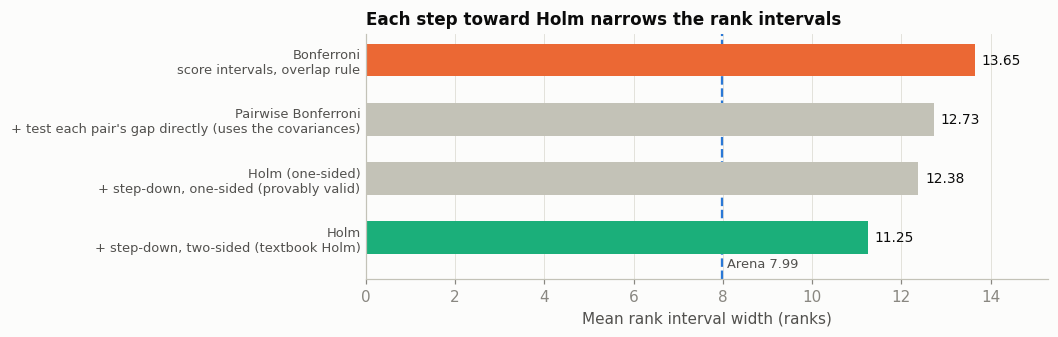

,Mean width,Change from the previous step,Bar where it stops (|z|)
Bonferroni,13.65,NaN,NaN
Pairwise Bonferroni,12.73,-0.92,4.52
Holm (one-sided),12.38,-0.34,4.39
Holm,11.25,-1.13,3.96


In [4]:
steps = ["bonferroni", "pairwise_bonferroni", "holm_onesided", "holm"]
what = {"bonferroni": "score intervals, overlap rule",
        "pairwise_bonferroni": "+ test each pair's gap directly (uses the covariances)",
        "holm_onesided": "+ step-down, one-sided (provably valid)",
        "holm": "+ step-down, two-sided (textbook Holm)"}
w = summary.loc["rank interval width, mean"]
fig, ax = plt.subplots(figsize=(8, 2.9))
y = np.arange(len(steps))[::-1]
for yi, p in zip(y, steps):
    ax.barh(yi, w[p], height=0.55, color=COLOR.get(p, AXIS), zorder=2)
    ax.text(w[p] + 0.15, yi, f"{w[p]:.2f}", va="center", fontsize=9, color=INK)
ax.axvline(w["arena"], color=COLOR["arena"], lw=1.5, ls="--", zorder=1)
ax.text(w["arena"] + 0.1, y[-1] - 0.45, f"Arena {w['arena']:.2f}", ha="left", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{PROCS[p]}\n{what[p]}" for p in steps], fontsize=8.5)
ax.tick_params(axis="y", labelcolor=INK2, length=0)
ax.set_xlim(0, w["bonferroni"] * 1.12)
ax.set_ylim(y[-1] - 0.7, y[0] + 0.45)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean rank interval width (ranks)")
ax.set_title("Each step toward Holm narrows the rank intervals")
plt.show()

pd.DataFrame({"Mean width": w[steps].round(2), "Change from the previous step": w[steps].diff().round(2),
              "Bar where it stops (|z|)": [np.nan] + [round(stop(p), 2) for p in steps[1:]]},
             index=steps).rename(index=PROCS)

- **Testing the gap directly** saves 0.9 ranks (13.65 → 12.73). The overlap rule compares a gap with $\mathrm{SE}_A + \mathrm{SE}_B$, which overstates the gap's uncertainty by a factor of about 1.37 on this data. That costs more than the move from $M = 129$ to $K = 8{,}256$ tests (3.55 → 4.52) adds.
- **The one-sided step-down** saves another 0.34 ranks.
- **The textbook two-sided step-down** saves 1.1 ranks more, the largest single step. This is the step that rests on simulation rather than proof (Section 1), which is why Section 5 tests it with many nearly tied pairs.

## 4. Result 3: where the width goes

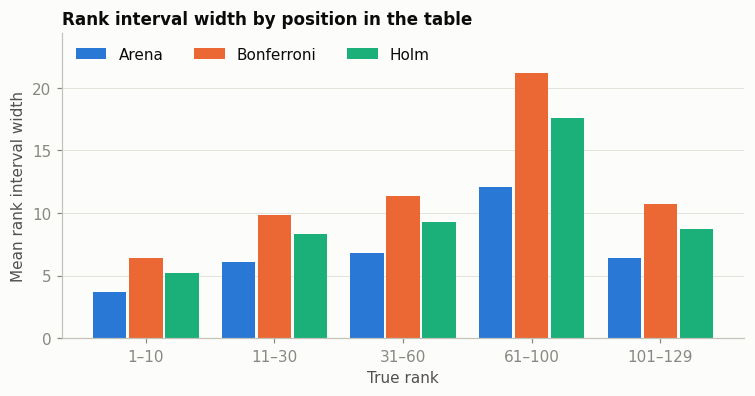

,Arena,Bonferroni,Pairwise Bonferroni,Holm (one-sided),Holm
True rank,,,,,
1–10,3.7,6.4,5.8,5.7,5.2
11–30,6.1,9.9,9.2,9.0,8.3
31–60,6.8,11.3,10.5,10.2,9.3
61–100,12.1,21.2,19.9,19.4,17.6
101–129,6.4,10.7,9.9,9.6,8.7


In [5]:
show = ["arena", "bonferroni", "holm"]
tiers = pd.cut(per_model.true_rank, [0, 10, 30, 60, 100, M], labels=["1–10", "11–30", "31–60", "61–100", f"101–{M}"])
width = per_model.groupby(tiers, observed=True)[[f"{p}_mean_width" for p in PROCS]].mean()
width.columns = list(PROCS.values())
width.index.name = "True rank"

fig, ax = plt.subplots(figsize=(8, 3.6))
x, bw = np.arange(len(width)), 0.26
for k, p in enumerate(show):
    ax.bar(x + (k - 1) * (bw + 0.02), width[PROCS[p]], width=bw, color=COLOR[p], label=PROCS[p], zorder=2)
ax.set_xticks(x, width.index)
ax.set_xlabel("True rank")
ax.set_ylabel("Mean rank interval width")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
ax.set_ylim(0, width.values.max() * 1.15)
ax.set_title("Rank interval width by position in the table")
plt.show()

width.round(1)

Holm narrows Bonferroni's rank intervals in every part of the table, by 16–19%. In absolute terms it saves the most where the table is crowded: for true ranks 61–100, intervals shrink from 21.2 to 17.6 ranks. Near the top, where models are well separated, Holm's intervals are only about 1.5 ranks wider than Arena's (5.2 against 3.7 for the top 10).

## 5. Result 4: stress tests, where the guarantees are tight

In the default world every procedure reaches 100%, not 95%. The reason is that a wrong ordering needs a pair whose true gap is close to zero: for a pair whose true gap is $\delta$ standard errors, the chance of declaring it in the wrong direction is about $\Phi(-\delta - \text{bar})$, which is negligible unless $\delta \approx 0$. Bonferroni-type bounds are built for the worst case, in which all $K$ pairs are exactly tied, and the real 2024 strengths have very few exact ties.

To test the procedures where their guarantees bind, we rerun the same simulation (same comparison graph, same battle counts, 1,000 replicates each) with the true strengths changed:

- **scaled by 0.5, 0.25 or 0.1:** models packed closer together across the whole table;
- **20 or 10 tiers:** models sorted into tiers of about 6 or 13, with every model in a tier given the tier's mean strength. The 354 or 768 within-tier pairs are exactly tied, and any ordering declared among them is wrong. The tiers are far apart, so most between-tier pairs are rejected early and Holm's bar falls far (to 3.96 with 20 tiers, 4.01 with 10). This is where FWER bounds are tight. Errors on exactly tied pairs are rejections of a true $H_0$, which Holm's theorem covers;
- **20 tiers with a small spread:** the same tiers, but each model keeps 5%, 10% or 20% of its distance from the tier mean, so the median within-tier gap is about 0.1, 0.2 or 0.4 standard errors. No pair is tied, so every error is a wrong direction on a nearly tied pair, tested after Holm's bar has fallen to 3.96. This is the case the textbook Holm has no proof for;
- **all tied:** every model has the same strength, so any declared ordering is wrong.

In [6]:
worlds = {"": "Default (2024 strengths)", "_scale0.5": "Strengths × 0.5", "_scale0.25": "Strengths × 0.25",
          "_scale0.1": "Strengths × 0.1", "_tiers20": "20 tiers, exactly tied", "_tiers10": "10 tiers, exactly tied",
          "_tiers20s0.05": "20 tiers, spread 5%", "_tiers20s0.1": "20 tiers, spread 10%",
          "_tiers20s0.2": "20 tiers, spread 20%", "_scale0": "All models tied"}
stress = {w: pd.read_csv(R(f"q2{w}_summary.csv"), index_col=0) for w in worlds}
SIM = "rank interval coverage, simultaneous (all models)"
cov_tab = pd.DataFrame({PROCS[p]: {name: cell(stress[w], SIM, p) for w, name in worlds.items()} for p in PROCS})
cov_tab.index.name = "All rank intervals right"
cov_tab

,Arena,Bonferroni,Pairwise Bonferroni,Holm (one-sided),Holm
All rank intervals right,,,,,
Default (2024 strengths),90.9% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
Strengths × 0.5,90.1% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
Strengths × 0.25,91.4% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
Strengths × 0.1,91.5% ± 0.9,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0
"20 tiers, exactly tied",24.1% ± 1.4,100.0% ± 0.0,99.8% ± 0.1,99.6% ± 0.2,97.5% ± 0.5
"10 tiers, exactly tied",7.3% ± 0.8,99.9% ± 0.1,99.8% ± 0.1,99.5% ± 0.2,96.6% ± 0.6
"20 tiers, spread 5%",66.8% ± 1.5,100.0% ± 0.0,99.9% ± 0.1,99.9% ± 0.1,99.4% ± 0.2
"20 tiers, spread 10%",70.3% ± 1.4,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,99.8% ± 0.1
"20 tiers, spread 20%",78.2% ± 1.3,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0,100.0% ± 0.0


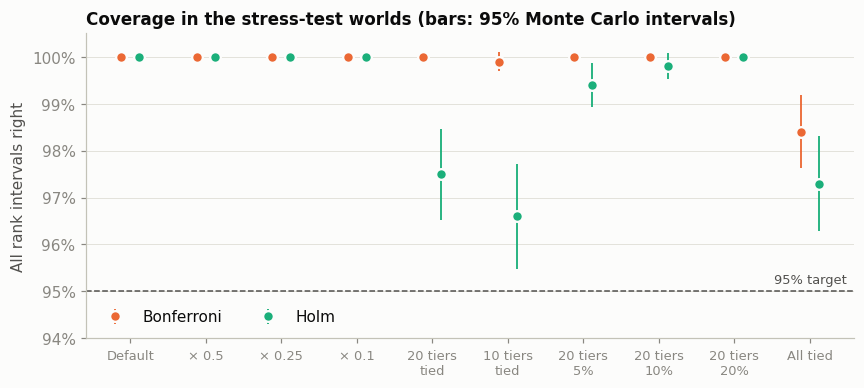

,Arena,Bonferroni,Pairwise Bonferroni,Holm (one-sided),Holm
Datasets with any wrong ordering,,,,,
Default (2024 strengths),15.5% ± 1.1,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0
Strengths × 0.5,29.5% ± 1.4,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0
Strengths × 0.25,44.3% ± 1.6,0.1% ± 0.1,0.0% ± 0.0,0.0% ± 0.0,0.1% ± 0.1
Strengths × 0.1,64.4% ± 1.5,0.1% ± 0.1,0.1% ± 0.1,0.1% ± 0.1,0.1% ± 0.1
"20 tiers, exactly tied",80.1% ± 1.3,0.0% ± 0.0,0.3% ± 0.2,0.5% ± 0.2,3.1% ± 0.5
"10 tiers, exactly tied",92.7% ± 0.8,0.1% ± 0.1,0.2% ± 0.1,0.5% ± 0.2,3.4% ± 0.6
"20 tiers, spread 5%",50.8% ± 1.6,0.0% ± 0.0,0.1% ± 0.1,0.1% ± 0.1,1.7% ± 0.4
"20 tiers, spread 10%",46.6% ± 1.6,0.0% ± 0.0,0.0% ± 0.0,0.0% ± 0.0,0.4% ± 0.2
"20 tiers, spread 20%",34.2% ± 1.5,0.0% ± 0.0,0.0% ± 0.0,0.1% ± 0.1,0.6% ± 0.2


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6))
xs = np.arange(len(worlds))
for off, p in [(-0.12, "bonferroni"), (0.12, "holm")]:
    v = np.array([stress[w].loc[SIM, p] for w in worlds])
    se = np.array([stress[w].loc[SIM, f"{p}_mc_se"] for w in worlds])
    ax.errorbar(xs + off, v, yerr=1.96 * se, fmt="o", ms=7, color=COLOR[p], mec=SURFACE, mew=1.5,
                elinewidth=1.2, capsize=0, label=PROCS[p], zorder=3)
ax.axhline(0.95, color=INK2, lw=1, ls="--", zorder=1)
ax.text(len(worlds) - 0.5, 0.951, "95% target", ha="right", va="bottom", fontsize=8.5, color=INK2)
ax.set_xticks(xs, ["Default", "× 0.5", "× 0.25", "× 0.1", "20 tiers\ntied", "10 tiers\ntied", "20 tiers\n5%",
                   "20 tiers\n10%", "20 tiers\n20%", "All tied"], fontsize=8.5)
ax.set_ylim(0.94, 1.005)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_ylabel("All rank intervals right")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncol=2)
ax.set_title("Coverage in the stress-test worlds (bars: 95% Monte Carlo intervals)")
plt.show()

fo = "[declared orderings] P(any false ordering)"
pd.DataFrame({PROCS[p]: {name: cell(stress[w], fo, p) for w, name in worlds.items()} for p in PROCS}) \
  .rename_axis("Datasets with any wrong ordering")

- **Holm reaches the target in every world.** Its lowest coverage is 96.6% ± 0.6 (10 exactly tied tiers), and its chance of declaring any wrong ordering is never above 3.4% ± 0.6. The pairwise Bonferroni and one-sided Holm have more room to spare (at least 97.3%).
- **Exact ties are the hardest case for Holm, and they are the case its theorem covers.** With 20 exactly tied tiers, Holm's bar falls to 3.96 and it declares a false ordering in 3.1% of datasets, against 0.3% for the pairwise Bonferroni. That is about what the bar implies: a tied pair clears a two-sided bar of 3.96 with probability $7.6 \times 10^{-5}$, and $354 \times 7.6 \times 10^{-5} = 2.7\%$. With 10 tiers the same union bound gives 4.6% against 3.4% observed, since the tied pairs' statistics are positively correlated and their failures overlap.
- **Near-ties, the unproven case, are easier.** Once the 20 tiers keep a small spread, every error is a wrong direction, and Holm's bar is just as low (3.96). Holm's chance of any wrong ordering falls from 3.1% (exact ties) to 1.7% ± 0.4 (5% spread), 0.4% ± 0.2 (10%) and 0.6% ± 0.2 (20%). Its coverage is at least 99.4%. This matches the heuristic in Section 1: the chance of a wrong direction is largest for an exact tie and falls as the gap grows, so a nearly tied pair is safer than a tied one.
- **With all models tied** the three pairwise procedures have the same coverage, 97.3%. Every declared ordering is then wrong, and all three declare something exactly when the largest |z| clears the same first bar, 4.52. The rate is below 5% because the 8,256 tests are positively correlated, and Bonferroni's union bound counts them as if they could fail separately.
- **Arena fails badly when ties exist.** All its rank spreads are right in only 24% (20 tiers) and 7% (10 tiers) of datasets, 67–78% with a small spread, and 0.2% when every model is tied.
- **Shrinking all gaps uniformly is not a hard case.** With strengths scaled down to 0.1, every corrected procedure still reaches 100%: few pairs are close enough to be at risk compared with the tiered worlds. A pair that is close but not tied is rarely declared in the wrong direction at a bar near 4: a true gap of one standard error makes that about 100 times less likely than for a tied pair.

## 6. Result 5: the real 2024 leaderboard

All procedures applied to the real battles (the fit behind the 2024-08-12 leaderboard). This is Arena's method recomputed on the public battle dump, not the published board itself. The dump has 129 models against the board's 128, and the 2024 board showed only each model's best rank, offset by hidden models (see Step 0 in the README). The figure shows the top 20 models by score.

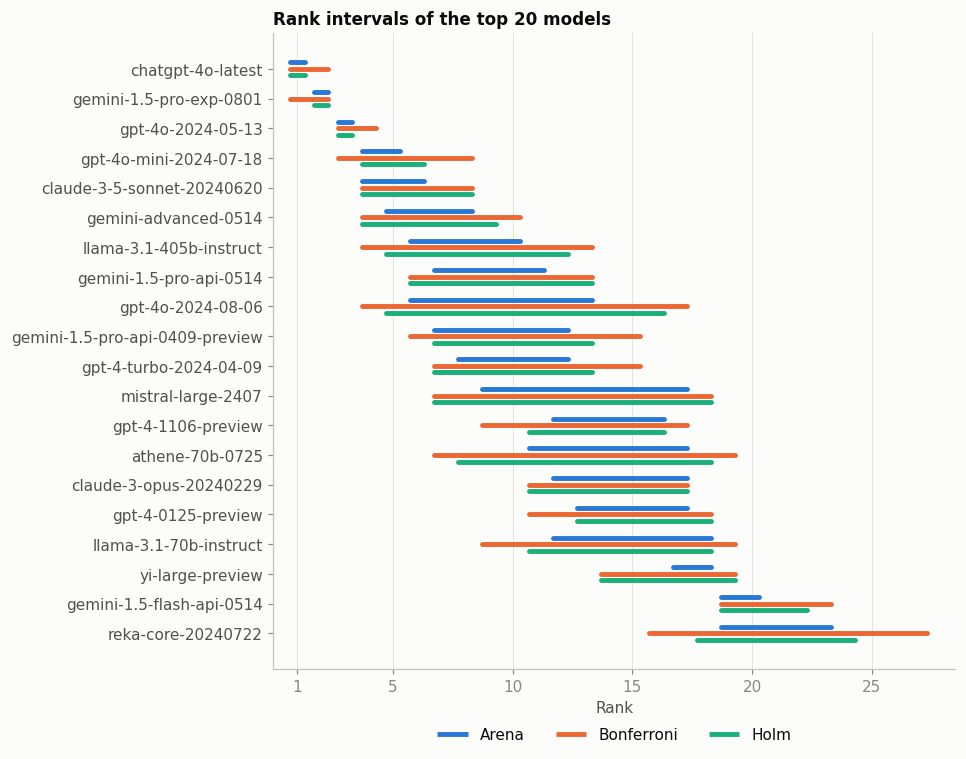

,Arena,Bonferroni,Pairwise Bonferroni,Holm (one-sided),Holm
Mean rank interval width,7.9,13.8,12.7,12.3,11.4
Widest rank interval,19,34,33,33,30
Models with a single rank,4,0,3,3,3
"Model pairs told apart (of 8,256)","7,808","7,430","7,499","7,525","7,585"
Top three models,"1–1, 2–2, 3–3","1–2, 1–2, 3–4","1–1, 2–2, 3–3","1–1, 2–2, 3–3","1–1, 2–2, 3–3"


In [8]:
top = real.head(20).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8, 7.5))
for off, p in zip([0.22, 0, -0.22], show):
    ax.hlines(y + off, top[f"{p}_best"] - 0.3, top[f"{p}_worst"] + 0.3, color=COLOR[p], lw=3.2, capstyle="round",
              label=PROCS[p])
ax.set_yticks(y, top.model)
ax.tick_params(axis="y", labelcolor=INK2)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
ax.set_xlim(0, top[[f"{p}_worst" for p in show]].values.max() + 1.5)
ax.set_xlabel("Rank")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3)
ax.set_title("Rank intervals of the top 20 models")
plt.show()

wd = {p: real[f"{p}_worst"] - real[f"{p}_best"] + 1 for p in PROCS}
pd.DataFrame({
    "Mean rank interval width": {p: f"{wd[p].mean():.1f}" for p in PROCS},
    "Widest rank interval": {p: int(wd[p].max()) for p in PROCS},
    "Models with a single rank": {p: int((wd[p] == 1).sum()) for p in PROCS},
    f"Model pairs told apart (of {K:,})": {p: f"{int(pairs[p].sum()):,}" for p in PROCS},
    "Top three models": {p: ", ".join(f"{b}–{w}" for b, w in zip(real[f"{p}_best"][:3], real[f"{p}_worst"][:3]))
                         for p in PROCS},
}).T.rename(columns=PROCS)

- **Holm keeps the top of the table sharp.** The top three models (chatgpt-4o-latest, gemini-1.5-pro-exp-0801, gpt-4o-2024-05-13) each keep a single rank, as under Arena. Bonferroni's intervals tie the top two. Over the whole table, Holm's intervals are 2.4 ranks narrower than Bonferroni's on average (11.4 against 13.8).
- **Holm agrees with every Bonferroni ordering and adds 155 more** (7,585 against 7,430).

How do Holm's orderings compare with Arena's, pair by pair?

In [9]:
agree = pd.crosstab(pairs.arena.map({True: "Arena: ordered", False: "Arena: not ordered"}),
                    pairs.holm.map({True: "Holm: ordered", False: "Holm: not ordered"}))
display(agree)

n_rej = int(pairs.holm.sum())
print(f"Holm's bar on the real fit: {norm.isf(LEVEL / (2 * (K - n_rej))):.2f} (it stopped after {n_rej:,} of {K:,} pairs); "
      f"Arena's overlap rule, in units of z, needs {(Z_ARENA * ratio).min():.2f} to {(Z_ARENA * ratio).max():.2f}")

# Two meanings of "tied": Arena's score intervals overlap (so Arena declares no ordering), or the two models' rank
# spreads overlap, which is what the site shows as a tie (it also covers pairs whose intervals are separate)
rk = real.set_index("model")
rank_sep = lambda p: rk.loc[pairs.model_hi, f"{p}_worst"].values < rk.loc[pairs.model_lo, f"{p}_best"].values
ci_tie, site_tie, holm_rank_sep = ~pairs.arena.values, ~rank_sep("arena"), rank_sep("holm")
display(pd.DataFrame({
    "Pairs Arena treats as tied": [ci_tie.sum(), site_tie.sum()],
    "…that Holm's test orders": [(ci_tie & pairs.holm).sum(), (site_tie & pairs.holm).sum()],
    "…whose Holm rank intervals are separate": [(ci_tie & holm_rank_sep).sum(), (site_tie & holm_rank_sep).sum()],
    "Pairs Arena separates": [(~ci_tie).sum(), (~site_tie).sum()],
    "…that Holm does not": [(~ci_tie & ~pairs.holm).sum(), (~site_tie & ~holm_rank_sep).sum()],
}, index=["Score intervals overlap (Arena's ordering rule)", "Rank spreads overlap (what the site shows)"]).T)

holm,Holm: not ordered,Holm: ordered
arena,,
Arena: not ordered,448,0
Arena: ordered,223,7585


Holm's bar on the real fit: 3.96 (it stopped after 7,585 of 8,256 pairs); Arena's overlap rule, in units of z, needs 2.14 to 3.39


,Score intervals overlap (Arena's ordering rule),Rank spreads overlap (what the site shows)
Pairs Arena treats as tied,448,830
…that Holm's test orders,0,178
…whose Holm rank intervals are separate,0,0
Pairs Arena separates,7808,7426
…that Holm does not,223,428


In [10]:
arena_only = pairs[pairs.arena & ~pairs.holm]
print(f"{len(arena_only)} orderings Arena declares and Holm does not: |z| from {arena_only.z.min():.2f} to {arena_only.z.max():.2f}")
per = (pd.concat([arena_only.model_hi, arena_only.model_lo]).value_counts().rename("Arena orderings Holm drops")
       .to_frame().join(rk[["rating", "battles"]]))
per = per.assign(rank_by_score=rk.rating.rank(ascending=False).loc[per.index].astype(int))
print(f"{len(per)} of {M} models are in at least one of them; the 10 with the most:")
display(per.head(10)[["rank_by_score", "rating", "battles", "Arena orderings Holm drops"]].round(1))

top20 = set(real.model.head(20))
(arena_only[arena_only.model_hi.isin(top20) & arena_only.model_lo.isin(top20)]
 .assign(gap=lambda d: d.rating_hi - d.rating_lo)
 [["model_hi", "model_lo", "gap", "se_diff", "z"]].round(2).sort_values("z")
 .rename(columns={"model_hi": "Arena puts this model…", "model_lo": "…above this one", "gap": "Score gap",
                  "se_diff": "SE of the gap", "z": "z"}).reset_index(drop=True))

223 orderings Arena declares and Holm does not: |z| from 2.49 to 3.96
117 of 129 models are in at least one of them; the 10 with the most:


,rank_by_score,rating,battles,Arena orderings Holm drops
codellama-70b-instruct,100,931.2,1193.0,13
gpt-3.5-turbo-0314,69,995.1,5655.0,11
dolphin-2.2.1-mistral-7b,93,951.4,1714.0,11
llama-2-13b-chat,92,952.1,19740.0,10
nous-hermes-2-mixtral-8x7b-dpo,80,973.3,3843.0,9
phi-3-mini-4k-instruct,91,954.9,21129.0,9
wizardlm-13b,95,947.4,7192.0,9
reka-flash-21b-20240226-online,46,1044.5,16056.0,8
openchat-3.5,85,965.2,8117.0,8
zephyr-7b-beta,96,942.2,11330.0,8


,Arena puts this model…,…above this one,Score gap,SE of the gap,z
0,gpt-4o-2024-08-06,gpt-4-1106-preview,8.31,3.30,2.52
1,gpt-4-turbo-2024-04-09,athene-70b-0725,7.77,2.84,2.74
2,gemini-1.5-pro-api-0409-preview,athene-70b-0725,8.61,2.97,2.90
3,claude-3-5-sonnet-20240620,llama-3.1-405b-instruct,7.32,2.45,2.99
4,athene-70b-0725,yi-large-preview,9.01,2.94,3.06
5,gemini-1.5-pro-api-0514,mistral-large-2407,8.96,2.87,3.12
6,llama-3.1-405b-instruct,gpt-4-turbo-2024-04-09,7.36,2.33,3.16
7,yi-large-preview,reka-core-20240722,12.86,3.74,3.44
8,claude-3-5-sonnet-20240620,gpt-4o-2024-08-06,11.94,3.37,3.55
9,gpt-4o-2024-08-06,claude-3-opus-20240229,11.52,3.23,3.57


- **Arena's method declares 223 orderings that Holm does not support.** Their $|z|$ lie between 2.5 and 3.96: each is clearly significant on its own, but none survives the correction for 8,256 comparisons. They involve 117 of the 129 models. The ten most affected sit in the crowded lower half of the table (score ranks 46 to 100), where many models are within a few points of each other. Among the top 20 models, they are the 17 pairs listed above: neighbours or near-neighbours with score gaps of 6 to 15 points. At the level of what the site displays, 428 pairs whose rank spreads are separate under Arena's method have overlapping Holm rank intervals.
- **Holm separates nothing that Arena shows as tied, under either meaning of "tied".** The proposal asked which apparent ties could be resolved, and the answer is none.
  - *Score intervals overlap* (448 pairs): Arena's overlap rule is conservative only by the factor $(\mathrm{SE}_A + \mathrm{SE}_B)/\mathrm{SE}(\text{gap})$, so its bar is between 2.1 and 3.4 in units of $z$. That is always below Holm's 3.96, and whatever the rule leaves unordered, Holm leaves unordered too.
  - *Rank spreads overlap* (830 pairs, the site's definition): Holm's test does order 178 of these pairs, but Arena's interval rule orders all of them as well. They look tied on the site only because rank spreads are coarser than the orderings behind them. Holm's own rank intervals separate none of the 830.

## 7. How much more could the correlations buy?

Holm, like Bonferroni, ignores that the 8,256 statistics are correlated (every model appears in 128 pairs). A procedure that uses the correlations exactly is the **max-|z| test**: draw score vectors from $N(0, V)$ with the real fit's covariance, and take the 95th percentile of $\max_{\text{pairs}} |z|$ as the bar. It is valid for the same reason as the pairwise Bonferroni (a false ordering requires its pair's centered $|z|$ to exceed the bar). Its step-down version, which recomputes the bar over the pairs not yet declared (Romano and Wolf 2005), is the correlation-aware analogue of the textbook Holm, with the same caveat about wrong directions. We compute both on the real fit only.

In [11]:
V, r = cov["V"], cov["ratings"]
iu = np.triu_indices(M, 1)
sd = np.sqrt(np.diag(V)[iu[0]] + np.diag(V)[iu[1]] - 2 * V[iu])
z_real = np.abs(r[iu[0]] - r[iu[1]]) / sd
evals, evecs = np.linalg.eigh(V)                    # V has rank M - 1 (scores sum to zero)
root = evecs * np.sqrt(np.clip(evals, 0, None))
rng = np.random.default_rng(2024)
B = 20_000
draws = np.vstack([np.abs(((Z := rng.standard_normal((2_000, M)) @ root.T)[:, iu[0]] - Z[:, iu[1]]) / sd).astype(np.float32)
                   for _ in range(B // 2_000)])  # B x K null |z| (660 MB as float32)

bar_single = np.quantile(draws.max(1), 1 - LEVEL)
declared = np.zeros(K, bool)
while True:   # step-down: bar = 95th percentile of the max over the pairs not yet declared
    bar = np.quantile(draws[:, ~declared].max(1), 1 - LEVEL)
    new = ~declared & (z_real > bar)
    if not new.any():
        break
    declared |= new
del draws

holm_bar = pairs.loc[~pairs.holm, "z"].abs().max()
pd.DataFrame({
    "Bar (|z|)": [f"{Z_PAIR:.2f}", f"{bar_single:.2f}", "—", f"{bar:.2f} where it stops"],
    "Pairs told apart": [int(pairs.pairwise_bonferroni.sum()), int((z_real > bar_single).sum()), int(pairs.holm.sum()),
                         int(declared.sum())],
}, index=["Pairwise Bonferroni", "Max-|z|, single step", "Holm", "Max-|z|, step-down"])

,Bar (|z|),Pairs told apart
Pairwise Bonferroni,4.52,7499
"Max-|z|, single step",4.30,7534
Holm,—,7585
"Max-|z|, step-down",3.86 where it stops,7603


Using the correlations helps only a little. The single-step max-|z| bar is 4.30 against Bonferroni's 4.52: the 8,256 correlated tests behave like about 3,000 independent ones. That gains fewer pairs than Holm's step-down does. The step-down max-|z| procedure combines both ideas, but its bar stops at 3.86 instead of Holm's 3.96, and it tells apart only 18 more pairs than Holm (7,603 against 7,585). It would cost 20,000 Monte Carlo draws per dataset, so we did not add it to the simulation. Holm captures most of what a pairwise FWER procedure can gain here.

## Takeaways

1. **Pairwise tests with Holm keep the rank intervals right.** All rank intervals were right in every one of the 1,000 simulated datasets. In the stress-test worlds they were all right in at least 96.6% of datasets, both with exact ties (where the guarantees bind) and with near-ties (where the textbook Holm has no proof).
2. **Holm gives the narrowest valid rank intervals of any correction so far:** 11.3 ranks on average, against 13.6 for Bonferroni, 33.1 for χ² Scheffé and 43.4 for the χ² projection. On the real leaderboard, the top three models each keep a single rank.
3. **The gain has two sources.** Testing each gap directly instead of checking whether intervals overlap saves 0.9 ranks. Holm's step-down saves 1.5 more, because thousands of clearly different pairs lower the bar for the rest from 4.52 to 3.96.
4. **The step-down is only proven for the one-sided version, which gains little.** The textbook two-sided Holm is not proven to control wrong directions under correlation. In every world we tried, its chance of any wrong ordering stayed below 5%: at most 3.4% with exact ties, which Holm's theorem covers, and at most 1.7% with near-ties, which it does not.
5. **On the real data, Holm does not support 223 of the orderings Arena's method declares, and it resolves none of Arena's ties**, whether a tie means overlapping score intervals or overlapping rank spreads. In this data the overlap rule is conservative only by a factor of about 1.4, far less than a correction for 8,256 comparisons requires.
6. **All FWER procedures overshoot here,** because only exactly or nearly tied pairs can produce errors, and the 2024 strengths have few such pairs. Closing the gap to the oracle's 8.5 ranks would take a procedure that adapts to how many pairs are actually close, or a weaker target such as BH's false discovery rate.

**Limitations.** As in Q1 and the other Q2 notebooks, the simulation is one idealized world (129 models with 2024 strengths, independent battles, exact Bradley–Terry); the stress tests change only the strengths, not the comparison graph or the battle counts. The z-tests rely on the normal approximation for each estimated gap; for the least-played models this is the weakest point. The two-sided Holm's control of wrong directions rests on the simulation, not on a theorem, and the near-tie worlds are one family of hard cases, not all of them. The real-data comparison uses one snapshot, recomputed from the public dump rather than read off the published board. With today's roughly 400 models there would be about 80,000 pairs, and every bar would rise (pairwise Bonferroni to about 5.0).

## Reproduce

```bash
python test_pairwise.py      # procedures agree with statsmodels; nesting, transitivity; real-fit checks
python q2.py --reps 1000 --procedures arena,bonferroni,chi2,chi2_scheffe,pairwise_bonferroni,holm_onesided,holm
for a in "--beta-scale 0.5" "--beta-scale 0.25" "--beta-scale 0.1" "--tiers 20" "--tiers 10" "--beta-scale 0"; do
  python q2.py --reps 1000 $a --procedures arena,bonferroni,chi2,chi2_scheffe,pairwise_bonferroni,holm_onesided,holm
done                          # about 4 minutes each; they can run in parallel
jupyter nbconvert --to notebook --execute --inplace notebook/q2_holm.ipynb
```

**References.** Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics.* · Shaffer, J. P. (1980). Control of directional errors with stagewise multiple test procedures. *Annals of Statistics.* · Finner, H. (1999). Stepwise multiple test procedures and control of directional errors. *Annals of Statistics.* · Guo, W. and Romano, J. P. On stepwise control of directional errors under independence and some dependence. arXiv:1602.02854. · Romano, J. P. and Wolf, M. (2005). Exact and approximate stepdown methods for multiple hypothesis testing. *JASA.*